# Análise Exploratória de Dados — UrbanPulse AI

Este notebook explora a demanda horária (`cnt`) do Bike Sharing Dataset. Ele usa o Parquet preparado em `data/processed/hour.parquet`; não altera os arquivos de origem nem realiza limpeza, transformação adicional ou modelagem.

As visualizações são descritivas. Associação visual não demonstra causalidade, e os padrões observados se referem ao sistema e ao período coberto pelos dados (2011–2012). Execute as células de cima para baixo.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

# Localiza a raiz do projeto a partir do diretório atual ou de seus pais.
candidates = (Path.cwd(), *Path.cwd().parents)
PROJECT_ROOT = next(
    (path for path in candidates if (path / "data/processed/hour.parquet").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Não encontrei data/processed/hour.parquet. Execute o notebook a partir da pasta do projeto ou de notebooks/."
    )

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "hour.parquet"
df = pd.read_parquet(DATA_PATH)
sns.set_theme(style="whitegrid", context="notebook")

print(f"Arquivo: {DATA_PATH.relative_to(PROJECT_ROOT)}")
print(f"Dimensões: {df.shape[0]:,} linhas × {df.shape[1]} colunas")
print(f"Período: {df['datetime'].min()} a {df['datetime'].max()}")
display(df.dtypes.rename("tipo").to_frame())

Arquivo: data\processed\hour.parquet
Dimensões: 17,379 linhas × 18 colunas
Período: 2011-01-01 00:00:00 a 2012-12-31 23:00:00


,tipo
instant,int64
dteday,str
season,int64
yr,int64
mnth,int64
hr,int64
holiday,int64
weekday,int64
workingday,int64
weathersit,int64


## Estatísticas descritivas da demanda

`cnt` representa o total de aluguéis em cada intervalo de uma hora. A tabela resume tendência central, dispersão, extremos e quartis; não representa uma previsão nem descreve a distribuição de cada subgrupo temporal.

In [2]:
cnt = df["cnt"]
cnt_stats = pd.Series(
    {
        "Média": cnt.mean(),
        "Mediana": cnt.median(),
        "Desvio padrão amostral": cnt.std(),
        "Mínimo": cnt.min(),
        "1º quartil (25%)": cnt.quantile(0.25),
        "2º quartil (50%)": cnt.quantile(0.50),
        "3º quartil (75%)": cnt.quantile(0.75),
        "Máximo": cnt.max(),
    },
    name="aluguéis por hora",
)
display(cnt_stats.to_frame().round(2))

,aluguéis por hora
Média,189.46
Mediana,142.00
Desvio padrão amostral,181.39
Mínimo,1.00
1º quartil (25%),40.00
2º quartil (50%),142.00
3º quartil (75%),281.00
Máximo,977.00


## Demanda média por hora do dia

Cada ponto mostra a média de `cnt` para aquele código de hora. Compare o perfil ao longo do dia; a média pode ocultar diferenças entre dias úteis, fins de semana e épocas do ano.

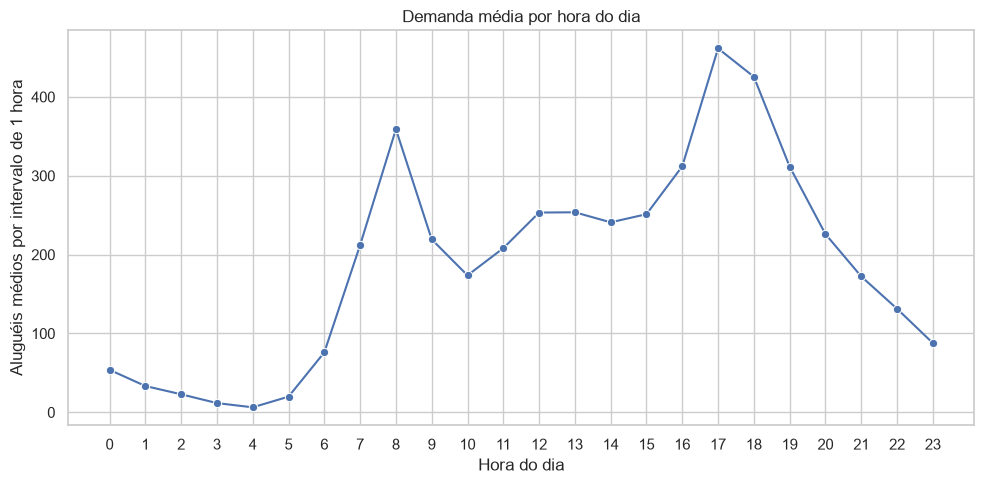

In [3]:
hourly_mean = df.groupby("hr", as_index=False)["cnt"].mean()
fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=hourly_mean, x="hr", y="cnt", marker="o", ax=ax)
ax.set(title="Demanda média por hora do dia", xlabel="Hora do dia", ylabel="Aluguéis médios por intervalo de 1 hora")
ax.set_xticks(range(24))
fig.tight_layout()
plt.show()

## Demanda média por dia da semana

O eixo horizontal mantém os códigos `weekday` de 0 a 6, conforme registrados no dataset. Consulte a documentação da fonte para associar códigos aos dias. A agregação reúne todos os anos e meses e, por isso, não isola efeitos de calendário.

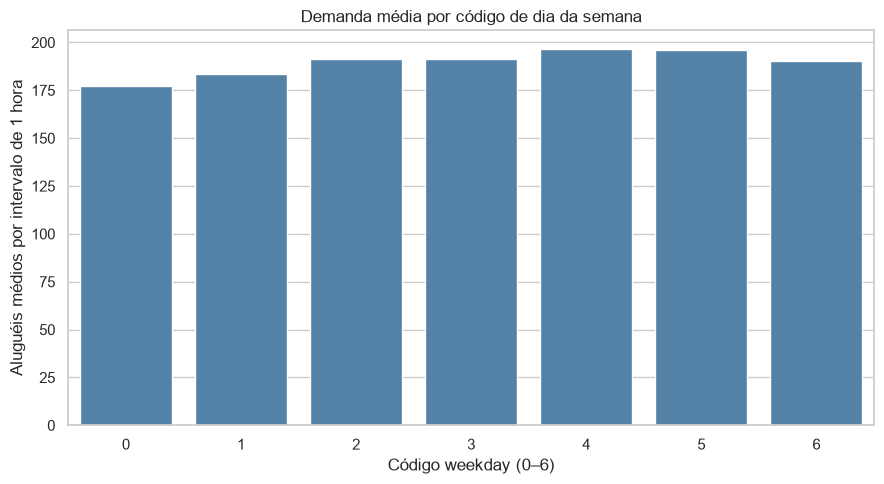

In [4]:
weekday_mean = df.groupby("weekday", as_index=False)["cnt"].mean()
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=weekday_mean, x="weekday", y="cnt", color="steelblue", ax=ax)
ax.set(title="Demanda média por código de dia da semana", xlabel="Código weekday (0–6)", ylabel="Aluguéis médios por intervalo de 1 hora")
fig.tight_layout()
plt.show()

## Demanda média mensal por ano

As linhas mostram médias mensais separadas pelos códigos de ano `yr` (0 = 2011; 1 = 2012). A comparação é descritiva e cobre apenas esses dois anos; não permite atribuir diferenças a um fator específico.

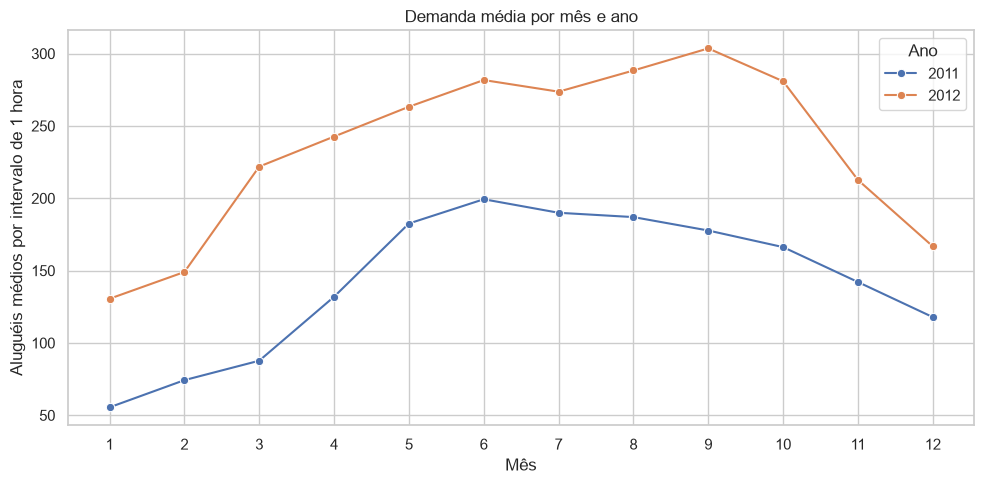

In [5]:
monthly_mean = df.groupby(["mnth", "yr"], as_index=False)["cnt"].mean()
monthly_mean["Ano"] = monthly_mean["yr"].map({0: "2011", 1: "2012"})
fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=monthly_mean, x="mnth", y="cnt", hue="Ano", marker="o", ax=ax)
ax.set(title="Demanda média por mês e ano", xlabel="Mês", ylabel="Aluguéis médios por intervalo de 1 hora")
ax.set_xticks(range(1, 13))
ax.legend(title="Ano")
fig.tight_layout()
plt.show()

## Temperatura e demanda

Cada ponto representa um intervalo horário. `temp` é uma temperatura normalizada no dataset, não graus Celsius. A nuvem permite observar associação e dispersão; por si só não estabelece causalidade e pode refletir outros fatores não separados neste gráfico.

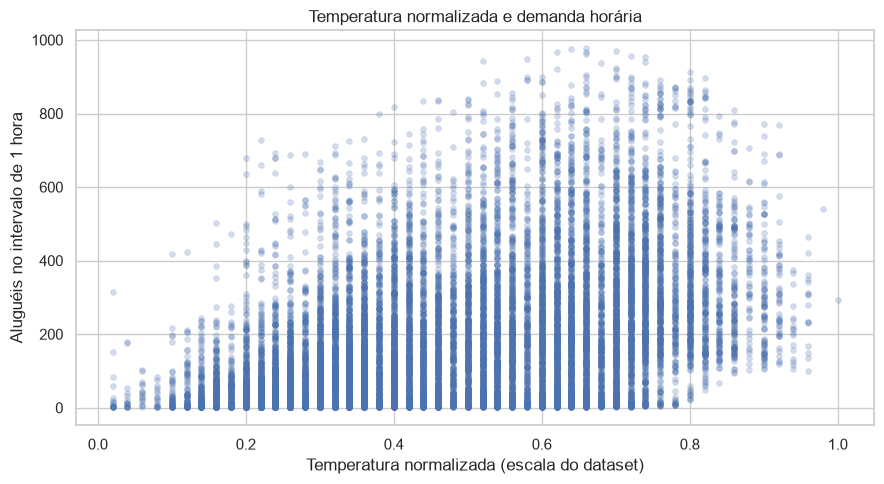

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=df, x="temp", y="cnt", alpha=0.25, s=18, edgecolor=None, ax=ax)
ax.set(title="Temperatura normalizada e demanda horária", xlabel="Temperatura normalizada (escala do dataset)", ylabel="Aluguéis no intervalo de 1 hora")
fig.tight_layout()
plt.show()

## Distribuição dos aluguéis por hora

O histograma mostra quantos intervalos horários caem em cada faixa de `cnt`, ajudando a avaliar concentração, dispersão e valores extremos. Como os intervalos não são separados por hora do dia ou calendário, o gráfico combina contextos distintos.

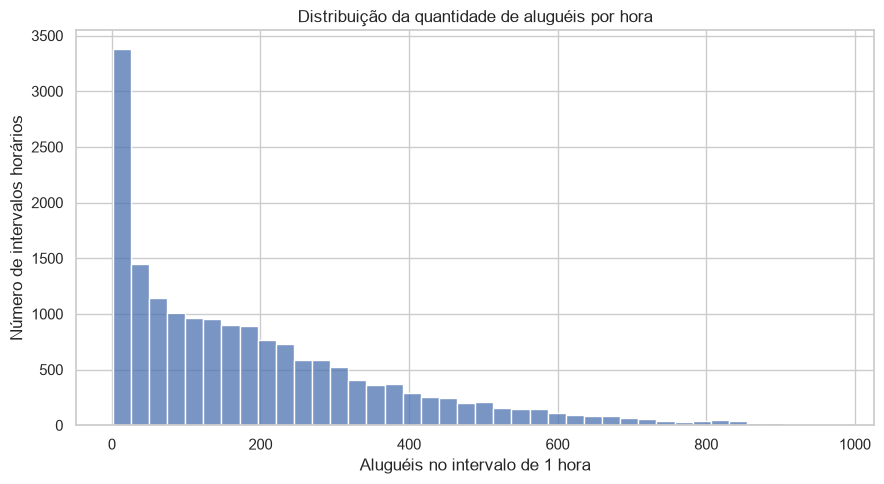

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=df, x="cnt", bins=40, ax=ax)
ax.set(title="Distribuição da quantidade de aluguéis por hora", xlabel="Aluguéis no intervalo de 1 hora", ylabel="Número de intervalos horários")
fig.tight_layout()
plt.show()

## Próximos passos

Use os gráficos como pontos de partida para perguntas mais específicas. Antes de qualquer inferência ou modelagem, considere a estrutura temporal dos registros e evite tratar observações próximas como amostras independentes. Nenhuma conclusão causal ou capacidade preditiva é produzida neste notebook.